<a href="https://colab.research.google.com/github/vaishaliverma21w-ship-it/lecture-2-of-DAM/blob/main/LECTURE_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Lecture 7

In [ ]:
#Method 1
import pandas as pd
file_path='/content/SkyBridge_Airline_Data (1).xlsx'
df=pd.read_excel()

In [3]:
import pandas as pd

#Method 2
raw=pd.read_excel("/content/SkyBridge_Airline_Data (1).xlsx",sheet_name="Unclean_Data")
#The 9 numeric columns we will study
num_cols=["Passengers","Ticket_Price","Delay_Minutes","Flight_Duration_Min","Fuel_Cost","Ancillary_Revenue","Baggage_Complaints","Customer_Rating","Crew_Overtime_Hours"]
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (120, 12)


,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
0,2026-01-01,SB-001,Delhi-Mumbai,143.0,5650.0,26.0,133.0,429.0,60600.0,2.0,3.9,NaN
1,2026-01-02,SB-002,Delhi-Bengaluru,158.0,7200.0,18.0,163.0,528.0,67600.0,3.0,4.1,6.3
2,2026-01-03,SB-003,Delhi-Bengaluru,178.0,6200.0,6.0,169.0,585.0,71700.0,3.0,4.4,5.3
3,2026-01-04,SB-004,Delhi-Mumbai,145.0,5800.0,9.0,131.0,433.0,61400.0,4.0,4.1,4.0
4,2026-01-05,SB-005,Delhi-Mumbai,159.0,5450.0,18.0,130.0,428.0,70000.0,2.0,4.0,8.7


In [4]:
raw.isnull().sum()

,0
Date,0
Flight_ID,0
Route,4
Passengers,5
Ticket_Price,7
Delay_Minutes,6
Flight_Duration_Min,4
Fuel_Cost,6
Ancillary_Revenue,6
Baggage_Complaints,5


In [5]:
total_blank=raw.isnull().sum().sum()
print("Blank cells:",total_blank)
print("Blank % :",round(total_blank/raw.size*100,1),"%")
print("Rows with at least one blank:",raw.isnull().any(axis=1).sum(),"out of",len(raw))

Blank cells: 58
Blank % : 4.0 %
Rows with at least one blank: 48 out of 120


In [ ]:
Blank cells  Heatmap

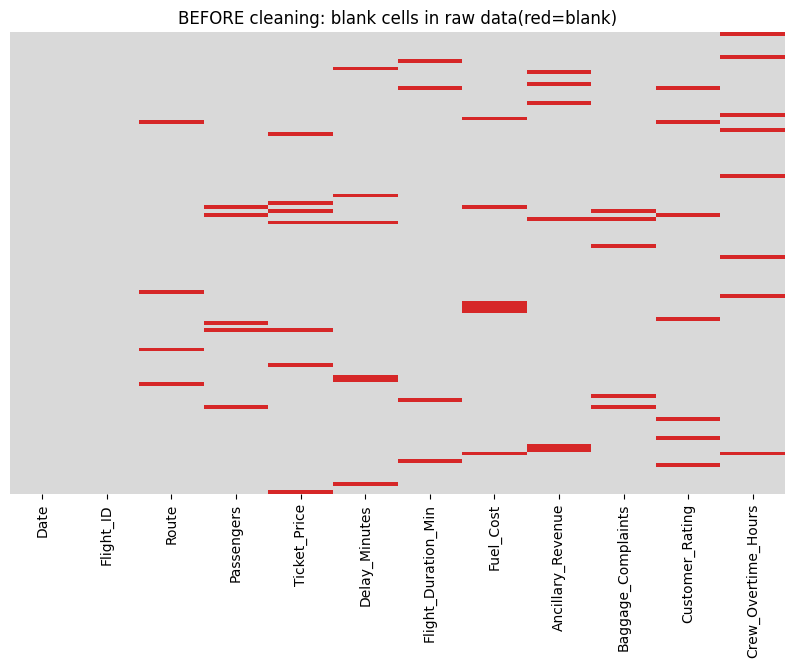

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
colors= ListedColormap(["#d9d9d9","#d62728"])
plt.figure(figsize=(10,6))
sns.heatmap(raw.isnull(),cmap=colors, cbar=False, yticklabels=False)
plt.title("BEFORE cleaning: blank cells in raw data(red=blank)")
plt.show()

In [10]:
# A big gap between mean and median is a warning sign
gap=pd.DataFrame({"Mean": raw[num_cols].mean(),
                  "Median": raw[num_cols].median()})
gap["Gap %"]=((gap["Mean"]- gap["Median"])/ gap["Median"]*100).round(1)
gap.round(1)

,Mean,Median,Gap %
Passengers,155.0,155.0,-0.0
Ticket_Price,6374.3,5900.0,8.0
Delay_Minutes,19.4,16.0,21.2
Flight_Duration_Min,157.2,165.0,-4.7
Fuel_Cost,511.2,530.0,-3.5
Ancillary_Revenue,59615.8,58800.0,1.4
Baggage_Complaints,3.1,3.0,3.5
Customer_Rating,4.2,4.1,1.8
Crew_Overtime_Hours,6.5,6.1,6.2


In [8]:
#step 1(for missing value_setting up rules for each variables)

In [11]:
rules = {
    "Passengers":         (0, 180),    # aircraft has 180 seats
    "Ticket_Price":       (1000, 20000), # domestic low-cost fare in INR
    "Delay_Minutes":      (0, 600),    # a delay cannot be negative
    "Flight_Duration_Min": (60, 240),  # domestic sector
    "Customer_Rating":    (1, 5),      # rating scale 1 to 5
}

for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))
    if len(bad) > 0:
        print(bad[["Date", "Flight_ID", col]].to_string(index=False))
    print()

Passengers -> impossible values: 1
      Date Flight_ID  Passengers
2026-02-07    SB-038       215.0

Ticket_Price -> impossible values: 1
      Date Flight_ID  Ticket_Price
2026-01-15    SB-015       57000.0

Delay_Minutes -> impossible values: 1
      Date Flight_ID  Delay_Minutes
2026-01-23    SB-023          -45.0

Flight_Duration_Min -> impossible values: 1
      Date Flight_ID  Flight_Duration_Min
2026-04-02    SB-092                410.0

Customer_Rating -> impossible values: 1
      Date Flight_ID  Customer_Rating
2026-03-18    SB-077              9.4



In [ ]:
# step 2 Time series plot

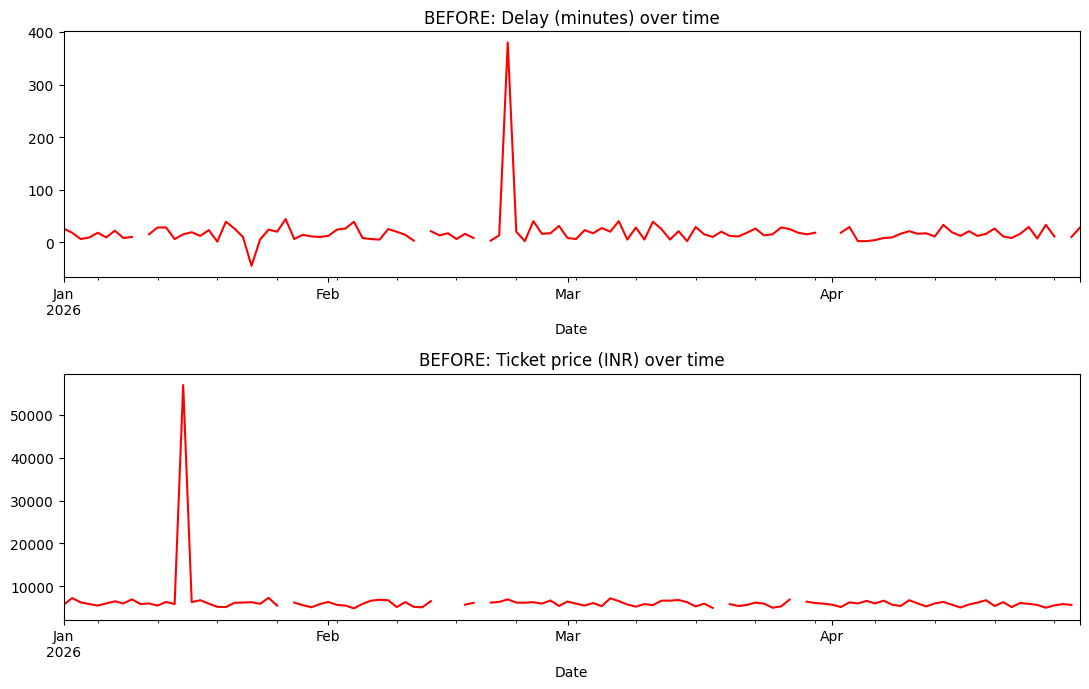

In [12]:
ts_raw = raw.set_index("Date")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))

ts_raw["Delay_Minutes"].plot(ax=axes[0], color="red", title="BEFORE: Delay (minutes) over time")
ts_raw["Ticket_Price"].plot(ax=axes[1], color="red", title="BEFORE: Ticket price (INR) over time")

plt.tight_layout()
plt.show()

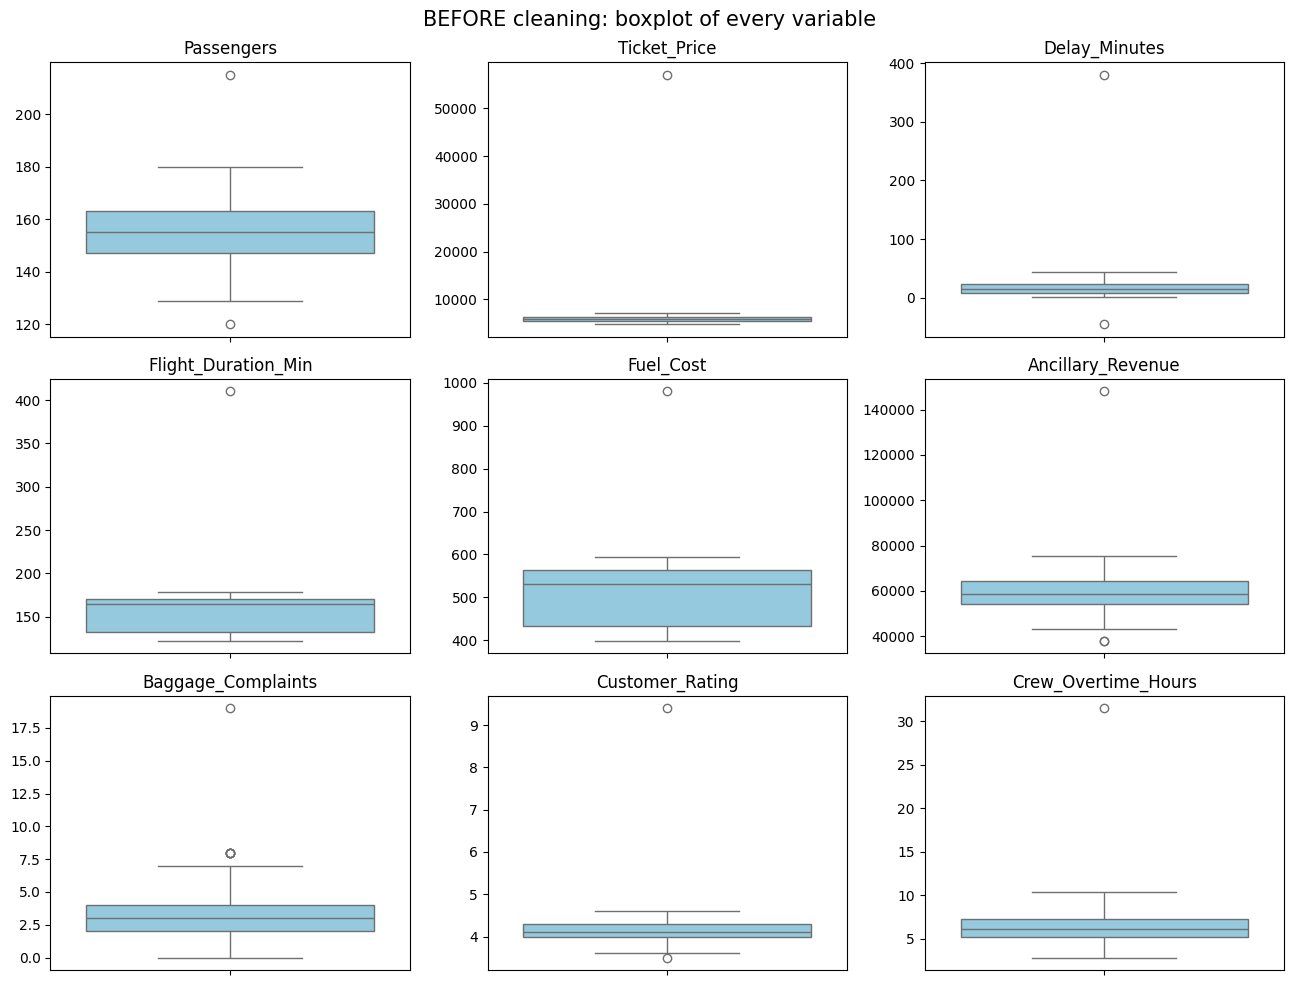

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
def show_boxplots(data, title):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(y=data[col], ax=axes[i], color="skyblue")
        axes[i].set_title(col)
        axes[i].set_ylabel("")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_boxplots(raw, "BEFORE cleaning: boxplot of every variable")


In [14]:
raw[raw["Delay_Minutes"]>100]

,Date,Flight_ID,Route,Passengers,Ticket_Price,Delay_Minutes,Flight_Duration_Min,Fuel_Cost,Ancillary_Revenue,Baggage_Complaints,Customer_Rating,Crew_Overtime_Hours
52,2026-02-22,SB-053,Delhi-Bengaluru,147.0,6900.0,380.0,173.0,980.0,62500.0,19.0,4.2,31.5


In [ ]:
# step 4 removing the impossible value

In [16]:
import numpy as np
# Create a copy
df= raw.copy()
#Find ratings below 1 or above 5
bad_values=(df["Customer_Rating"]< 1)| (df["Customer_Rating"]> 5)
# Count unusual ratings
print("Unusual ratings:", bad_values.sum())

# Replace unusual ratings with missing values
df.loc[bad_values, "Customer_Rating"] = np.nan

# Compare missing cells
print("Missing cells before:", raw.isnull().sum().sum())

print("Missing cells after:", df.isnull().sum().sum())


Unusual ratings: 1
Missing cells before: 58
Missing cells after: 59


In [ ]:
# Capping

In [17]:
# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Count values capped
capped_count = ((before < lower) | (before > upper)).sum()

print("Variable:", col)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower)
print("Upper limit:", upper)
print("Values capped:", capped_count)

# Compare before and after capping
print("\nBefore capping:")
print(before.describe())

print("\nAfter capping:")
print(df_capped[col].describe())

Variable: Ancillary_Revenue
Q1: 54425.0
Q3: 64225.0
IQR: 9800.0
Lower limit: 39725.0
Upper limit: 78925.0
Values capped: 3

Before capping:
count       114.000000
mean      59615.789474
std       11182.331029
min       37900.000000
25%       54425.000000
50%       58800.000000
75%       64225.000000
max      148000.000000
Name: Ancillary_Revenue, dtype: float64

After capping:
count      114.000000
mean     59040.131579
std       7590.232005
min      39725.000000
25%      54425.000000
50%      58800.000000
75%      64225.000000
max      78925.000000
Name: Ancillary_Revenue, dtype: float64


Maximum before: 148000.0
Maximum after: 78925.0
Upper limit: 78925.0


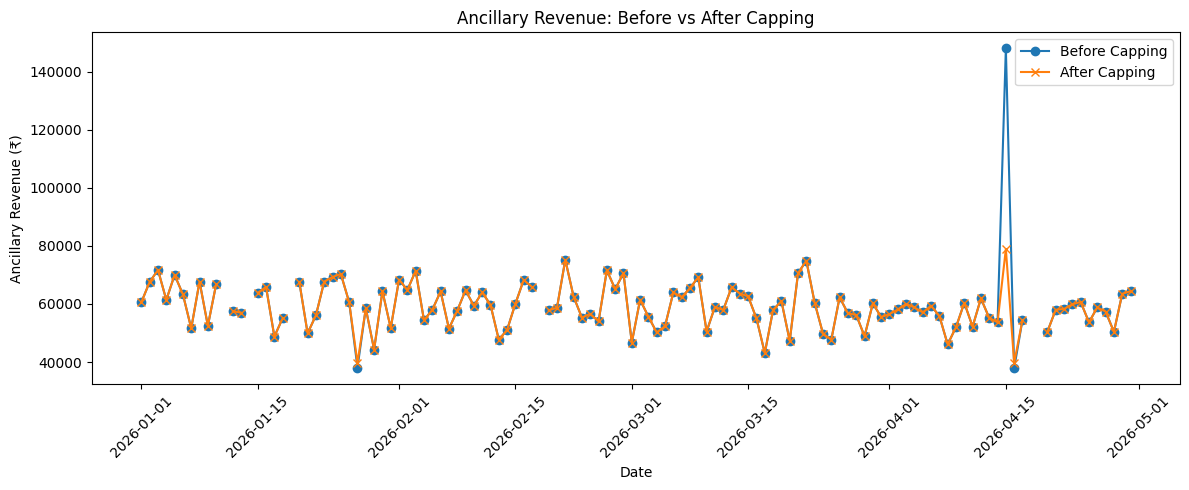

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Select the variable
col = "Ancillary_Revenue"

# Start with the original, uncapped data
before = raw[col].copy()

# Create a fresh dataset for capping
df_capped = raw.copy()

# Calculate Q1, Q3 and IQR using original data
Q1 = before.quantile(0.25)
Q3 = before.quantile(0.75)
IQR = Q3 - Q1

# Calculate the upper and lower limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Apply capping to the new dataset
df_capped[col] = before.clip(lower, upper)

# Print maximum values
print("Maximum before:", before.max())
print("Maximum after:", df_capped[col].max())
print("Upper limit:", upper)

# Plot before and after
plt.figure(figsize=(12, 5))

plt.plot(raw["Date"], before,
         label="Before Capping", marker="o")

plt.plot(raw["Date"], df_capped[col],
         label="After Capping", marker="x")

plt.title("Ancillary Revenue: Before vs After Capping")
plt.xlabel("Date")
plt.ylabel("Ancillary Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()